# Abstractive Summarization on XL-Sum (Hindi): mT5 vs mBART

This notebook fine-tunes and evaluates two multilingual seq2seq Transformers on the **Hindi** portion of
[XL-Sum](https://huggingface.co/datasets/csebuetnlp/xlsum):

| Model | Checkpoint |
|---|---|
| mT5 | `google/mt5-small` (swap to `mt5-base` if you have a bigger GPU) |
| mBART | `facebook/mbart-large-cc25` |

**Metrics:** ROUGE-1, ROUGE-2, ROUGE-L (with a Devanagari-aware tokenizer) and BERTScore using multilingual BERT (`bert-base-multilingual-cased`).

**Before running:** `Runtime -> Change runtime type -> T4 GPU` (or better).
The defaults are deliberately small (fast mode): the whole notebook should finish in roughly 15-25 minutes on a free T4, most of it model downloading and training. Increase `N_TRAIN`/`EPOCHS` later for better scores.

## 1. Install dependencies

In [1]:
!pip install -q "datasets<4.0.0" "transformers>=4.41" sentencepiece accelerate rouge_score bert_score protobuf

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


## 2. Imports and configuration

In [2]:
import os, re, gc, random, unicodedata, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM,
                          DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments)
from rouge_score import rouge_scorer
import bert_score

# ------------------ Configuration ------------------
LANGUAGE = "hindi"      # any XL-Sum language config: "nepali", "bengali", "telugu", ...
N_TRAIN  = 1500         # training examples (full Hindi train set is ~70k)
N_VAL    = 100
N_TEST   = 100
MAX_IN   = 256          # max source tokens
MAX_TGT  = 48           # max summary tokens
EPOCHS   = 2
SEED     = 42
# ---------------------------------------------------

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "NO GPU - enable one in Runtime settings!")

Device: cuda | Tesla T4


## 3. Load the XL-Sum dataset

In [3]:
try:
    raw = load_dataset("csebuetnlp/xlsum", LANGUAGE, trust_remote_code=True)
except Exception as e:
    print("Script-based loading failed (", type(e).__name__, ") -> falling back to the parquet export.")
    base = f"hf://datasets/csebuetnlp/xlsum@refs%2Fconvert%2Fparquet/{LANGUAGE}"
    raw = load_dataset("parquet", data_files={
        "train": f"{base}/train/0000.parquet",
        "validation": f"{base}/validation/0000.parquet",
        "test": f"{base}/test/0000.parquet"})

print(raw)

def subset(ds, n):
    return ds.shuffle(seed=SEED).select(range(min(n, len(ds))))

data = {"train": subset(raw["train"], N_TRAIN),
        "validation": subset(raw["validation"], N_VAL),
        "test": subset(raw["test"], N_TEST)}

ex = data["train"][0]
print("\nARTICLE :", ex["text"][:400], "...")
print("SUMMARY :", ex["summary"])

README.md:   0%|          | 0.00/14.6k [00:00<?, ?B/s]

xlsum.py:   0%|          | 0.00/4.55k [00:00<?, ?B/s]

data/hindi_XLSum_v2.0.tar.bz2: reconstructing file:   0%|          |  0.00B / 82.3MB            

data/hindi_XLSum_v2.0.tar.bz2: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 70778
    })
    test: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8847
    })
    validation: Dataset({
        features: ['id', 'url', 'title', 'summary', 'text'],
        num_rows: 8847
    })
})

ARTICLE : इस तरह यूनाइटेड लेजिस्लेटिव फ़ोरम की सरकार गोवा में सत्ता में आ गई है. इस सरकार में उप मुख्यमंत्री का पद एक निर्दलीय विधायक फ़िलिप रॉड्रीग्ज़ को दिया गया है. महत्वपूर्ण है कि इससे कुछ ही घंटे पहले गोवा के राज्यपाल ने भारतीय जनता पार्टी सरकार को बर्ख़ास्त कर दिया था. इससे पहले कुछ दिनों से संकट के बादल झेलती भाजपा सरकार ने विधानसभा में एक वोट से विवादास्पद विश्वास-मत हासिल किया था. विवाद तब उठा था  ...
SUMMARY : गोवा में भारतीय जनता पार्टी के बर्ख़ास्त होने के बाद, कांग्रेस के नेतृत्व वाले यूनाइटेड लेजिस्लेटिव फ़ोरम के नेता प्रताप सिंह राणे को बुधवार देर रात मुख्यमंत्री पद की शपथ दिलाई गई.


## 4. Evaluation metrics

* **ROUGE** – the default `rouge_score` tokenizer deletes every non-ASCII character, which would give all-zero scores for Hindi.
  We therefore plug in a Unicode-aware tokenizer that only strips punctuation (keeping Devanagari vowel signs intact).
* **BERTScore (mBERT)** – precision/recall/F1 from contextual embeddings of `bert-base-multilingual-cased` (layer 9, the library default for this model).

In [4]:
class UnicodeTokenizer:
    # Whitespace tokenizer that removes punctuation/symbols (incl. the Hindi danda) but keeps combining marks.
    def tokenize(self, text):
        text = "".join(" " if unicodedata.category(ch)[0] in "PS" else ch for ch in text.lower())
        return text.split()

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=UnicodeTokenizer())

def compute_rouge(preds, refs):
    agg = {"rouge1": [], "rouge2": [], "rougeL": []}
    for p, r in zip(preds, refs):
        s = scorer.score(r, p)
        for k in agg:
            agg[k].append(s[k].fmeasure)
    return {k: 100 * float(np.mean(v)) for k, v in agg.items()}

def compute_bertscore(preds, refs):
    P, R, F = bert_score.score(preds, refs, model_type="bert-base-multilingual-cased",
                               num_layers=9, batch_size=32, device=device, verbose=False)
    return {"bertscore_P": 100 * P.mean().item(), "bertscore_R": 100 * R.mean().item(), "bertscore_F1": 100 * F.mean().item()}

# sanity check: identical strings must give 100
print(compute_rouge(["मैं घर जा रहा हूँ।"], ["मैं घर जा रहा हूँ।"]))

{'rouge1': 100.0, 'rouge2': 100.0, 'rougeL': 100.0}


## 5. Generic train + evaluate routine

One function handles both models. mBART-specific details:
the tokenizer needs `src_lang`/`tgt_lang = hi_IN`, and generation starts from the `hi_IN` language token.
mT5 is trained in fp32 (fp16 is known to produce NaNs for T5-family models); mBART uses fp16 to fit on a T4. Validation during training is switched off to save time.

In [5]:
def run_experiment(name, checkpoint, is_mbart=False, lr=5e-4, bs=8, accum=2, fp16=False):
    print(f"\n{'='*70}\n{name}: {checkpoint}\n{'='*70}")
    set_seed()

    # ---- tokenizer ----
    if is_mbart:
        tok = AutoTokenizer.from_pretrained(checkpoint, src_lang="hi_IN", tgt_lang="hi_IN")
    else:
        tok = AutoTokenizer.from_pretrained(checkpoint)

    # ---- tokenise ----
    def preprocess(batch):
        enc = tok(batch["text"], max_length=MAX_IN, truncation=True)
        lab = tok(text_target=batch["summary"], max_length=MAX_TGT, truncation=True)
        enc["labels"] = lab["input_ids"]
        return enc

    cols = data["train"].column_names
    tokenized = {k: v.map(preprocess, batched=True, remove_columns=cols) for k, v in data.items()}

    # ---- model ----
    model = AutoModelForSeq2SeqLM.from_pretrained(checkpoint)
    print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.0f}M")
    collator = DataCollatorForSeq2Seq(tok, model=model, label_pad_token_id=-100)

    steps_per_epoch = -(-len(tokenized["train"]) // (bs * accum))
    warmup_steps = max(1, int(0.05 * steps_per_epoch * EPOCHS))

    args = Seq2SeqTrainingArguments(
        output_dir=f"./{name}_out",
        eval_strategy="no",
        save_strategy="no",
        learning_rate=lr,
        per_device_train_batch_size=bs,
        per_device_eval_batch_size=bs,
        gradient_accumulation_steps=accum,
        num_train_epochs=EPOCHS,
        weight_decay=0.01,
        warmup_steps=warmup_steps,
        optim="adafactor",              # low-memory optimiser
        fp16=fp16,
        gradient_checkpointing=False,
        logging_steps=25,
        report_to="none",
        seed=SEED,
    )
    model.config.use_cache = False
    trainer = Seq2SeqTrainer(model=model, args=args,
                             train_dataset=tokenized["train"],
                             data_collator=collator)

    t0 = time.time()
    trainer.train()
    train_min = (time.time() - t0) / 60
    history = [h for h in trainer.state.log_history if "loss" in h or "eval_loss" in h]

    # ---- generation on the test set ----
    model.config.use_cache = True
    model.eval()
    gen_kwargs = dict(max_new_tokens=MAX_TGT, num_beams=2, no_repeat_ngram_size=3,
                      length_penalty=1.0, early_stopping=True)
    if is_mbart:
        gen_kwargs["decoder_start_token_id"] = tok.convert_tokens_to_ids("hi_IN")

    texts, refs, preds = data["test"]["text"], data["test"]["summary"], []
    gbs = 16
    for i in range(0, len(texts), gbs):
        batch = tok(texts[i:i+gbs], max_length=MAX_IN, truncation=True, padding=True, return_tensors="pt").to(model.device)
        batch.pop("token_type_ids", None)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=fp16 and device == "cuda"):
            out = model.generate(**batch, **gen_kwargs)
        preds += tok.batch_decode(out, skip_special_tokens=True)
    preds = [p.strip() for p in preds]

    # ---- metrics ----
    res = {"model": name, "train_minutes": round(train_min, 1)}
    res.update(compute_rouge(preds, refs))
    res.update(compute_bertscore(preds, refs))
    print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in res.items()})

    del model, trainer
    gc.collect(); torch.cuda.empty_cache()
    return res, preds, history

## 6. Fine-tune and evaluate mT5

In [6]:
mt5_res, mt5_preds, mt5_hist = run_experiment(
    "mT5-small", "google/mt5-small", is_mbart=False, lr=5e-4, bs=8, accum=2, fp16=False)


mT5-small: google/mt5-small


config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

... (16 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'model': 'mT5-small', 'train_minutes': 2.7, 'rouge1': 26.83, 'rouge2': 7.63, 'rougeL': 20.7, 'bertscore_P': 74.08, 'bertscore_R': 70.39, 'bertscore_F1': 72.14}


## 7. Fine-tune and evaluate mBART

In [7]:
mbart_res, mbart_preds, mbart_hist = run_experiment(
    "mBART-cc25", "facebook/mbart-large-cc25", is_mbart=True, lr=5e-5, bs=4, accum=4, fp16=True)


mBART-cc25: facebook/mbart-large-cc25


config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

... (9 outputs left out)

[transformers] Both `max_new_tokens` (=48) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=48) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=48) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=48) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'model': 'mBART-cc25', 'train_minutes': 4.2, 'rouge1': 29.55, 'rouge2': 10.18, 'rougeL': 22.67, 'bertscore_P': 74.73, 'bertscore_R': 73.1, 'bertscore_F1': 73.87}


## 8. Comparison of results

,rouge1,rouge2,rougeL,bertscore_P,bertscore_R,bertscore_F1,train_minutes
model,,,,,,,
mT5-small,26.83,7.63,20.70,74.08,70.39,72.14,2.7
mBART-cc25,29.55,10.18,22.67,74.73,73.10,73.87,4.2


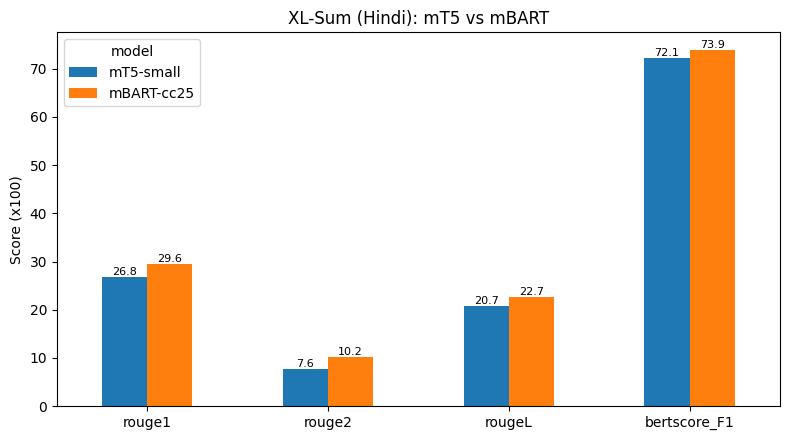

In [8]:
results = pd.DataFrame([mt5_res, mbart_res]).set_index("model")
cols = ["rouge1", "rouge2", "rougeL", "bertscore_P", "bertscore_R", "bertscore_F1", "train_minutes"]
results = results[cols].round(2)
results.to_csv("xlsum_results.csv")
display(results)

ax = results[["rouge1", "rouge2", "rougeL", "bertscore_F1"]].T.plot(kind="bar", figsize=(8, 4.5), rot=0)
ax.set_ylabel("Score (x100)"); ax.set_title(f"XL-Sum ({LANGUAGE.title()}): mT5 vs mBART")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout(); plt.savefig("comparison.png", dpi=150); plt.show()

### Training curves

/tmp/ipykernel_353/2301575139.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  for a in axes: a.set_xlabel("step"); a.legend()


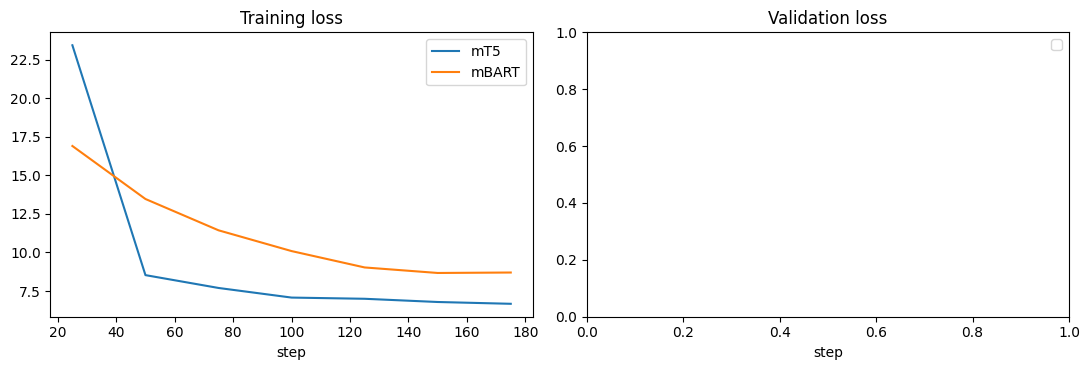

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for hist, label in [(mt5_hist, "mT5"), (mbart_hist, "mBART")]:
    tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
    if tr: axes[0].plot(*zip(*tr), label=label)
    if ev: axes[1].plot(*zip(*ev), marker="o", label=label)
axes[0].set_title("Training loss"); axes[1].set_title("Validation loss")
for a in axes: a.set_xlabel("step"); a.legend()
plt.tight_layout(); plt.show()

## 9. Qualitative examples

In [10]:
for i in random.Random(1).sample(range(len(data["test"])), 3):
    print("ARTICLE  :", data["test"][i]["text"][:300].replace("\n", " "), "...")
    print("REFERENCE:", data["test"][i]["summary"])
    print("mT5      :", mt5_preds[i])
    print("mBART    :", mbart_preds[i])
    print("-" * 100)

pd.DataFrame({"reference": data["test"]["summary"], "mT5": mt5_preds, "mBART": mbart_preds}).to_csv("predictions.csv", index=False)

ARTICLE  : एक अपुष्ट रिपोर्ट के अनुसार दो इराक़ी उत्तरी शहर तालाफ़ार में संघर्ष के दौरान मारे गए जबकि शनिवार को वहाँ 11 लोगों की मौत हो गई थी. उधर लातिफ़िया में एक अभियान में 12 इराक़ी पुलिसकर्मियों के मारे जाने की ख़बर है. इससे पहले इराक़ के रक्षा मंत्रालय ने ख़बर दी थी कि पूर्व राष्ट्रपति सद्दाम हुसैन के शास ...
REFERENCE: उत्तरी इराक़ में लगातार दूसरे दिन भी अमरीकी सैनिकों और विद्रोहियों के बीच ज़बरदस्त संघर्ष हुआ है. जबकि इराक़ी सेना का कहना है कि उसने दक्षिण में 500 संदिग्ध चरमपंथियों को गिरफ़्तार किया गया है.
mT5      : भारत के पूर्व राष्ट्रपति सद्दाम हुसैन अलदौरी को गिरफ़्तार कर लिया गया है.
mBART    : तैयारियां पूरी हो गई हैं और इराक़ी अधिकारियों ने कहा है कि लातिफ़िया और मूसल में चल रहे अमरीकी अभियान में पाँच सौ संदिग्ध लोगों को गिरफ़्तार किया गया है.
----------------------------------------------------------------------------------------------------
ARTICLE  : इस मॉल की ओर जाते हुए बाहर से सब ठीक ही नज़र आता है- सिवाय कुछ खिड़कियों के टूटे काँच के और दीवारों पर गोलियों के निश

## 10. Download outputs (optional)

In [11]:
from google.colab import files
for f in ["xlsum_results.csv", "predictions.csv", "comparison.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the report

* **ROUGE-1/2/L** measure unigram, bigram and longest-common-subsequence overlap (F1) between generated and reference summaries; **BERTScore** measures semantic similarity, so it is more tolerant of paraphrase.
* mBART-large (~610M params) usually outperforms mT5-small (~300M) at equal training budget; compare against `mt5-base` for a fairer size match.
* Scores here are from a **subset** of the data and only a few epochs. Increase `N_TRAIN`/`EPOCHS` (and use a stronger GPU) for results closer to the XL-Sum paper.
* To try another language, change `LANGUAGE` (and for mBART `hi_IN` -> e.g. `ne_NP`, `bn_IN`, `te_IN`).
* Reference: Hasan et al., *XL-Sum: Large-Scale Multilingual Abstractive Summarization for 44 Languages*, Findings of ACL 2021.